In [2]:
import cv2 
import tensorflow as tf
import os
import numpy as np 


data_dir = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Tomato_dataset'
    
valid_extensions = ['.jpeg', '.jpg', '.png' ,'bmp']

#test function
def is_valid_image(file_path):
    # 1. Check if the file extension is correct
    ext = os.path.splitext(file_path)[1].lower()
    if ext not in valid_extensions:
        return False
        
    # try opening the image with OpenCV
    img = cv2.imread(file_path)
    if img is None:
        return False
        
    return True

2026-05-06 17:48:19.276587: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778089699.495741      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778089699.558659      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778089700.070843      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778089700.070915      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778089700.070918      57 computation_placer.cc:177] computation placer alr

In [3]:
os.listdir(data_dir)

['Local', 'Export', 'Rotten']

In [3]:
#remove the bad images
for dir1 in os.listdir(data_dir):
    # print(dir1)
    for img in os.listdir(os.path.join(data_dir,dir1 )):
        full_img_path = os.path.join(data_dir, dir1,  img)
        if not is_valid_image(full_img_path):
            os.remove(full_img_path)

KeyboardInterrupt: 

In [5]:
!pip install split-folders

In [7]:
import splitfolders
from matplotlib import pyplot as plt

In [8]:
input_folder = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Tomato_dataset'
output_folder = '/kaggle/working/tomato_split' # Save to the writable directory

splitfolders.ratio(input_folder, 
                   output=output_folder, 
                   seed=42, 
                   ratio=(.8, .1, .1), # (train, val, test)
                   group_prefix=None, 
                   move=False) # Use False to copy files

Copying files: 15408 files [01:23, 185.30 files/s]


In [9]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224) 

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_ds.class_names
print("\n classes are:", class_names)

Found 12324 files belonging to 3 classes.


I0000 00:00:1778089965.958974      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Found 1539 files belonging to 3 classes.
Found 1545 files belonging to 3 classes.

 classes are: ['Export', 'Local', 'Rotten']


In [11]:
data_iterator = train_ds.as_numpy_iterator()

In [12]:
data_iterator

NumpyIterator(iterator=<tensorflow.python.data.ops.iterator_ops.OwnedIterator object at 0x785f7a24aba0>)

In [13]:
batch = data_iterator.next()

In [14]:
batch[1]

array([2, 0, 0, 1, 2, 2, 0, 2, 1, 2, 1, 0, 1, 0, 2, 0, 0, 2, 0, 0, 0, 1,
       2, 0, 0, 0, 2, 1, 1, 2, 0, 0], dtype=int32)

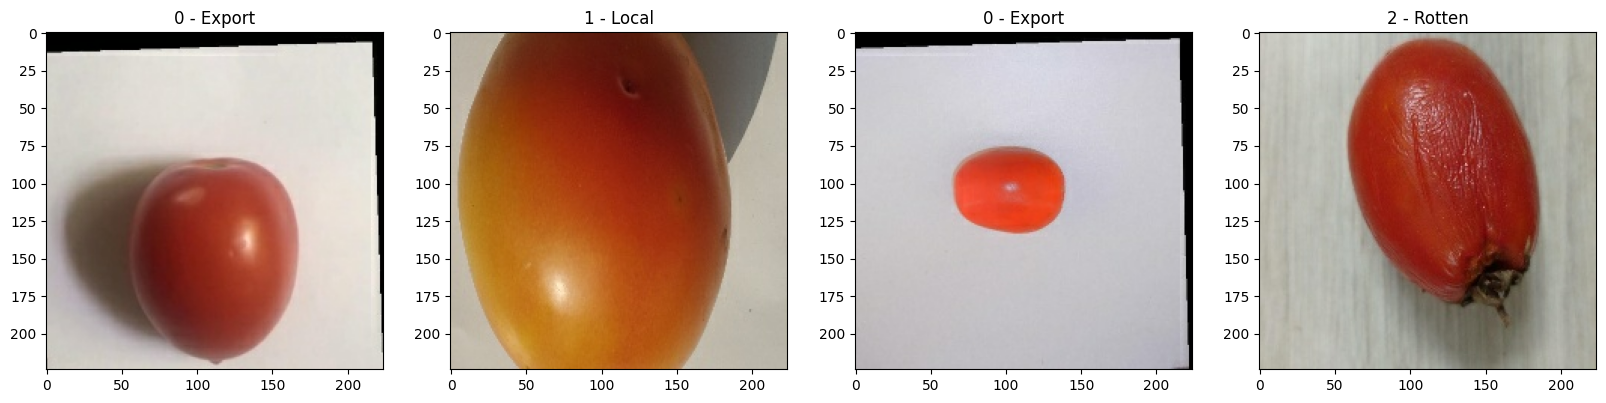

In [15]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))

start_idx = 11

for i in range(4):
    true_idx = start_idx + i 
    
    img = batch[0][true_idx]
    label_id = batch[1][true_idx]
    
    ax[i].imshow(img.astype(int))
    ax[i].title.set_text(f"{label_id} - {class_names[label_id]}")

#### Class 0: Export
#### Class 1: Local
#### Class 2: Rotten

In [16]:
Train_data = train_ds.map(lambda x,y: (x/255,y))

Val_data = val_ds.map(lambda x,y: (x/255,y))

Test_data = test_ds.map(lambda x,y: (x/255,y))

In [17]:
batch[0].max()

np.float32(255.0)

In [18]:
#scaled data min=0 and max = 1
scaled_batch = Train_data.as_numpy_iterator().next()
scaled_batch[0].max()

np.float32(1.0)

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense,GlobalAveragePooling2D, Flatten, Dropout

In [20]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Pour supprime le model precedent
tf.keras.backend.clear_session() 


model = Sequential([
    
    Input(shape=(224, 224, 3)),
    
    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.4),
    
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    
    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.4),
    
    Flatten(),
    
    Dense(256, activation='relu'),
    Dropout(0.5),
    
    Dense(3, activation='softmax')
])


model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,769,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,779,635 (10.60 MB)

 Trainable params: 2,779,635 (10.60 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
log_dir = "/kaggle/working/logs"
os.makedirs(log_dir, exist_ok=True)

In [22]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir)

In [23]:
hist =model.fit(Train_data, epochs=20 , validation_data=Val_data ,callbacks=[tensorboard_callback])

Epoch 1/20


I0000 00:00:1778089973.174542     149 service.cc:152] XLA service 0x785eac00c3b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778089973.174614     149 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1778089973.847095     149 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1778089979.500868     149 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


386/386 ━━━━━━━━━━━━━━━━━━━━ 23s 35ms/step - accuracy: 0.6385 - loss: 0.8138 - val_accuracy: 0.8811 - val_loss: 0.3351
Epoch 2/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8568 - loss: 0.3530 - val_accuracy: 0.8642 - val_loss: 0.3076
Epoch 3/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8993 - loss: 0.2561 - val_accuracy: 0.9201 - val_loss: 0.2143
Epoch 4/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9192 - loss: 0.2084 - val_accuracy: 0.9272 - val_loss: 0.1895
Epoch 5/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9381 - loss: 0.1691 - val_accuracy: 0.9292 - val_loss: 0.1687
Epoch 6/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9456 - loss: 0.1463 - val_accuracy: 0.9220 - val_loss: 0.2074
Epoch 7/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9485 - loss: 0.1430 - val_accuracy: 0.9240 - val_loss: 0.1916
Epoch 8/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9554 - loss: 0.1168 - val_accuracy: 0.93

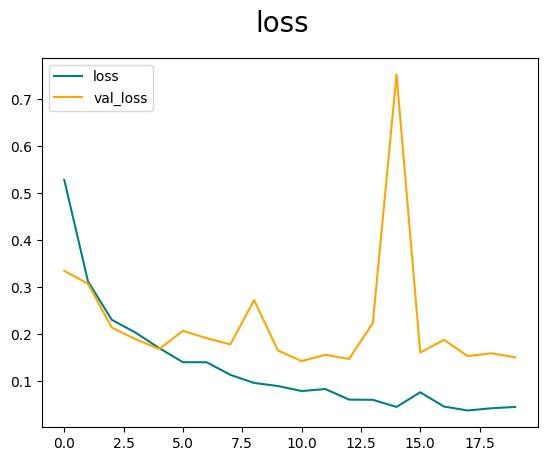

In [24]:
fig = plt.figure
plt.plot(hist.history['loss'],color='teal', label='loss')
plt.plot(hist.history['val_loss'],color='orange', label='val_loss')
plt.suptitle('loss',fontsize=20)
plt.legend(loc='upper left')
plt.show()

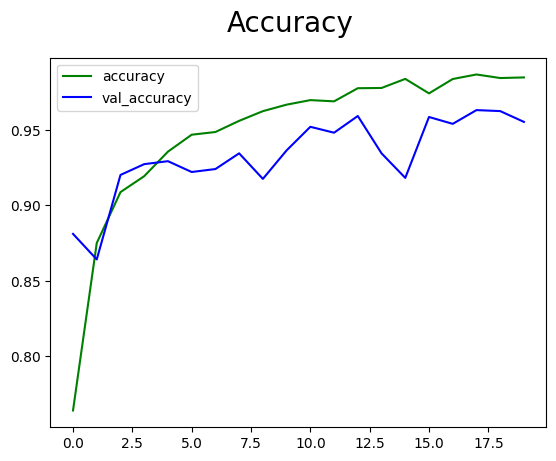

In [25]:
fig = plt.figure
plt.plot(hist.history['accuracy'],color='green', label='accuracy')
plt.plot(hist.history['val_accuracy'],color='blue', label='val_accuracy')
plt.suptitle('Accuracy',fontsize=20)
plt.legend(loc='upper left')
plt.show()

In [26]:
from sklearn.metrics import classification_report, confusion_matrix

y_true_all = []
y_pred_all = []


for batch in Test_data.as_numpy_iterator():
    X, y = batch
    
    
    y_predict_probs = model.predict(X, verbose=0)
    
    
    y_predict_classes = np.argmax(y_predict_probs, axis=1)
    
    
    y_true_all.extend(y)
    y_pred_all.extend(y_predict_classes)


print("Classification Report:")
print(classification_report(y_true_all, y_pred_all, target_names=['Local', 'Export', 'Rotten']))

Classification Report:
              precision    recall  f1-score   support

       Local       1.00      0.98      0.99       515
      Export       0.91      0.97      0.94       515
      Rotten       0.97      0.92      0.95       515

    accuracy                           0.96      1545
   macro avg       0.96      0.96      0.96      1545
weighted avg       0.96      0.96      0.96      1545



In [27]:
models_dir = "/kaggle/working/models"
os.makedirs(models_dir, exist_ok=True)

In [30]:
from tensorflow.keras.models import load_model
# save the model 
model.save(os.path.join(models_dir,'Tomato_grading_02.keras'))

In [31]:
model_path = '/kaggle/working/models/Tomato_grading_01.keras'

size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model size: {size_mb:.2f} MB")

Model size: 31.86 MB
